In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os

BASE_DIR = "/content/drive/MyDrive/road_data_shared"

print("Checking project directory...")

for root, dirs, files in os.walk(BASE_DIR):
    level = root.replace(BASE_DIR, '').count(os.sep)
    if level > 2:
        dirs[:] = []
        continue

    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}    {file}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checking project directory...
road_data_shared/
    split_manifest.json
    YOLOv8n_Road_Damage_Detection.ipynb
    Screenshot 2026-10-21 171240.png
    test_metrics.csv
    results.csv
    images/
        train/
            img-113.jpg
            img-100.jpg
            img-106.jpg
            img-101.jpg
            img-105.jpg
        val/
            img-104.jpg
            img-108.jpg
            img-109.jpg
            img-129.jpg
            img-115.jpg
        test/
            img-11.jpg
            img-114.jpg
            img-10.jpg
            img-107.jpg
            img-102.jpg
    annotations/
        train/
            img-1.xml
            img-100.xml
            img-103.xml
            img-113.xml
            img-110.xml
        val/
            img-109.xml
            img-104.xml
            img-108.xml
            img-115.xml
            im

In [ ]:

!pip install -q ultralytics pycocotools opencv-python-headless seaborn scikit-learn pandas matplotlib tqdm


In [ ]:

import torch
import torchvision
import cv2
import ultralytics
import sklearn
import pandas as pd
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("OpenCV:", cv2.__version__)
print("Ultralytics:", ultralytics.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Enable T4 GPU in Runtime settings.")

print("\nAll libraries imported successfully!")


PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA Available: True
OpenCV: 4.14.0
Ultralytics: 8.4.215
GPU: Tesla T4

All libraries imported successfully!


In [ ]:

from pathlib import Path
from glob import glob
import os

BASE_DIR = Path("/content/drive/MyDrive/road_data_shared")

# Original images
IMAGE_DIR = BASE_DIR / "images"

# Original XML annotations
ANNOTATION_DIR = BASE_DIR / "annotations"

# YOLO dataset
DATASET_DIR = BASE_DIR / "yolo_dataset"

# Test directories
TEST_IMAGES = IMAGE_DIR / "test"
TEST_LABELS = DATASET_DIR / "labels" / "test"

print("Images:", TEST_IMAGES)
print("YOLO labels:", TEST_LABELS)

print("\nDirectory verification:")
print("Images exist:", TEST_IMAGES.exists())
print("Labels exist:", TEST_LABELS.exists())


Images: /content/drive/MyDrive/road_data_shared/images/test
YOLO labels: /content/drive/MyDrive/road_data_shared/yolo_dataset/labels/test

Directory verification:
Images exist: True
Labels exist: True


In [ ]:

splits = ["train", "val", "test"]

for split in splits:
    img_dir = IMAGE_DIR / split
    label_dir = DATASET_DIR / "labels" / split
    xml_dir = ANNOTATION_DIR / split

    images = list(img_dir.glob("*.jpg"))
    labels = list(label_dir.glob("*.txt"))
    xmls = list(xml_dir.glob("*.xml"))

    print(f"\n{split.upper()} DATASET")
    print("Images:", len(images))
    print("YOLO labels:", len(labels))
    print("XML annotations:", len(xmls))



TRAIN DATASET
Images: 426
YOLO labels: 426
XML annotations: 426

VAL DATASET
Images: 106
YOLO labels: 106
XML annotations: 106

TEST DATASET
Images: 133
YOLO labels: 133
XML annotations: 133


In [ ]:

test_images = sorted(TEST_IMAGES.glob("*.jpg"))
test_labels = sorted(TEST_LABELS.glob("*.txt"))

image_names = {p.stem for p in test_images}
label_names = {p.stem for p in test_labels}

missing_labels = image_names - label_names
missing_images = label_names - image_names

print("Total test images:", len(image_names))
print("Total test labels:", len(label_names))

print("Images without labels:", len(missing_labels))
print("Labels without images:", len(missing_images))

if not missing_labels and not missing_images:
    print("\nSUCCESS: All test images have matching YOLO labels!")
else:
    print("Mismatches found!")
    print("Missing labels:", missing_labels)
    print("Missing images:", missing_images)


Total test images: 133
Total test labels: 133
Images without labels: 0
Labels without images: 0

SUCCESS: All test images have matching YOLO labels!


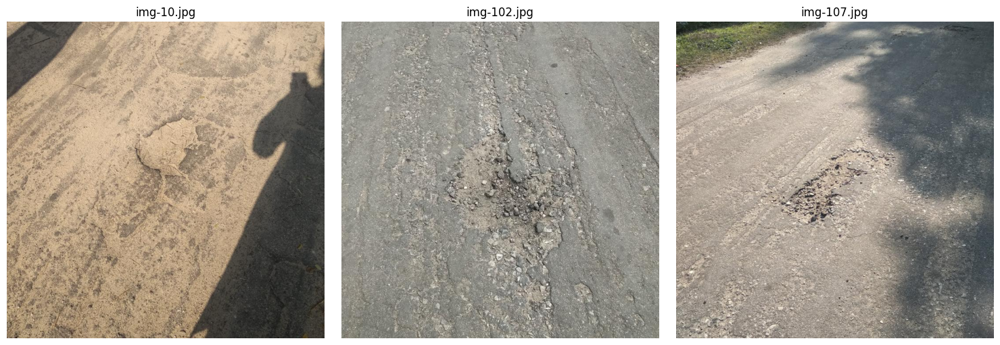

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, image_path in zip(axes, test_images[:3]):
    img = Image.open(image_path)
    ax.imshow(img)
    ax.set_title(image_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import os

pt_files = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.endswith(".pt"):
            path = os.path.join(root, file)
            size = os.path.getsize(path) / (1024 ** 2)
            pt_files.append((path, size))

print("AVAILABLE YOLO CHECKPOINTS\n")

for path, size in pt_files:
    print(f"{os.path.basename(path)} | {size:.2f} MB")
    print(path)
    print("-" * 60)


AVAILABLE YOLO CHECKPOINTS

yolo26n.pt | 5.29 MB
/content/drive/MyDrive/road_data_shared/yolo26n.pt
------------------------------------------------------------
best_n.pt | 6.21 MB
/content/drive/MyDrive/road_data_shared/best_n.pt
------------------------------------------------------------
best_s.pt | 21.48 MB
/content/drive/MyDrive/road_data_shared/best_s.pt
------------------------------------------------------------


In [ ]:

# Replace these with the actual paths printed in Cell 6

YOLOV8N_PATH = "/content/drive/MyDrive/road_data_shared/best_n.pt"

YOLOV8S_PATH = "/content/drive/MyDrive/road_data_shared/best_s.pt"


print("YOLOv8n:", os.path.exists(YOLOV8N_PATH))
print("YOLOv8s:", os.path.exists(YOLOV8S_PATH))


YOLOv8n: True
YOLOv8s: True


In [ ]:

import torch
from ultralytics import YOLO

device = 0 if torch.cuda.is_available() else "cpu"

model_n = YOLO(YOLOV8N_PATH)
model_s = YOLO(YOLOV8S_PATH)

print("YOLOv8n loaded successfully!")
print("YOLOv8s loaded successfully!")

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


YOLOv8n loaded successfully!
YOLOv8s loaded successfully!
Device: 0
GPU: Tesla T4


In [ ]:

print("YOLOv8n classes:", model_n.names)
print("YOLOv8s classes:", model_s.names)

assert len(model_n.names) == 1
assert len(model_s.names) == 1

print("\nBoth models are configured for single-class detection.")


YOLOv8n classes: {0: 'pothole'}
YOLOv8s classes: {0: 'pothole'}

Both models are configured for single-class detection.


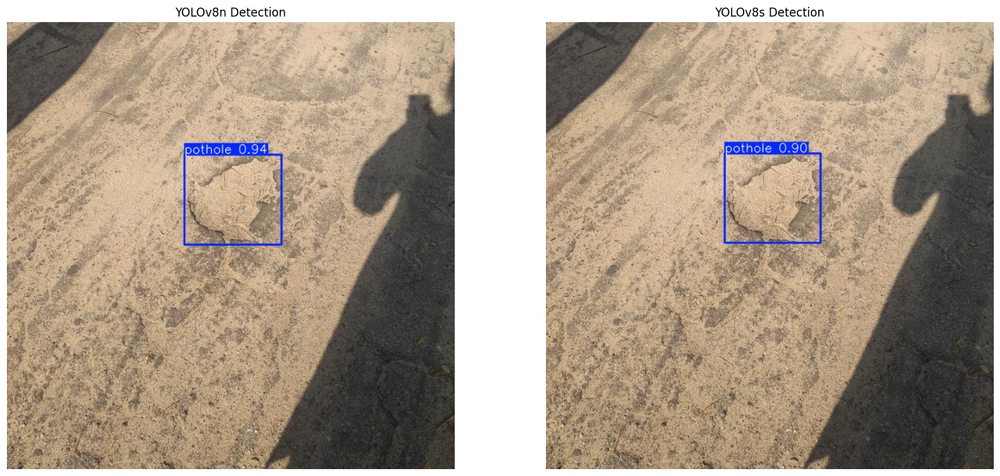

YOLOv8n detections: 1
YOLOv8s detections: 1


In [ ]:

import matplotlib.pyplot as plt

sample_image = str(test_images[0])

results_n = model_n.predict(
    source=sample_image,
    conf=0.25,
    device=device,
    verbose=False
)

results_s = model_s.predict(
    source=sample_image,
    conf=0.25,
    device=device,
    verbose=False
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(results_n[0].plot()[..., ::-1])
axes[0].set_title("YOLOv8n Detection")
axes[0].axis("off")

axes[1].imshow(results_s[0].plot()[..., ::-1])
axes[1].set_title("YOLOv8s Detection")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("YOLOv8n detections:", len(results_n[0].boxes))
print("YOLOv8s detections:", len(results_s[0].boxes))


In [ ]:

from pathlib import Path

# Use the top-level labels folder
YOLO_LABELS = BASE_DIR / "labels"

test_image_dir = BASE_DIR / "images" / "test"
test_label_dir = YOLO_LABELS / "test"

print("Test images:", len(list(test_image_dir.glob("*.jpg"))))
print("Test labels:", len(list(test_label_dir.glob("*.txt"))))

image_stems = {p.stem for p in test_image_dir.glob("*.jpg")}
label_stems = {p.stem for p in test_label_dir.glob("*.txt")}

print("Missing labels:", len(image_stems - label_stems))
print("Missing images:", len(label_stems - image_stems))

assert len(image_stems) == 133
assert image_stems == label_stems

print("\nTest dataset verified!")


Test images: 133
Test labels: 133
Missing labels: 0
Missing images: 0

Test dataset verified!


In [ ]:

import yaml

evaluation_config = {
    "path": str(BASE_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 1,
    "names": ["pothole"]
}

EVAL_YAML = "/content/road_damage_eval.yaml"

with open(EVAL_YAML, "w") as f:
    yaml.safe_dump(evaluation_config, f, sort_keys=False)

print(open(EVAL_YAML).read())
print("Evaluation configuration created!")


path: /content/drive/MyDrive/road_data_shared
train: images/train
val: images/val
test: images/test
nc: 1
names:
- pothole

Evaluation configuration created!


In [ ]:

print("Evaluating YOLOv8n on test dataset...")

metrics_n = model_n.val(
    data=EVAL_YAML,
    split="test",
    imgsz=640,
    batch=16,
    device=device,
    plots=True,
    project="/content/road_evaluation",
    name="yolov8n",
    exist_ok=True
)

print("\nYOLOv8n Evaluation Completed!")
print("Precision:", metrics_n.box.mp)
print("Recall:", metrics_n.box.mr)
print("mAP50:", metrics_n.box.map50)
print("mAP50-95:", metrics_n.box.map)


Evaluating YOLOv8n on test dataset...
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 51.2±16.5 MB/s, size: 60.5 KB)
val: Scanning /content/drive/MyDrive/road_data_shared/labels/test... 133 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 133/133 1.6it/s 1:23
val: New cache created: /content/drive/MyDrive/road_data_shared/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 3.6it/s 2.5s
                   all        133        299      0.739      0.692      0.773      0.511
Speed: 1.5ms preprocess, 5.6ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to /content/road_evaluation/yolov8n

YOLOv8n Evaluation Completed!
Precision: 0.7392098254275483
Recall: 0.6923076923076923
mAP50: 0.7726272741576863
mAP50-95: 0.511016962636768


In [ ]:

print("Evaluating YOLOv8s on test dataset...")

metrics_s = model_s.val(
    data=EVAL_YAML,
    split="test",
    imgsz=640,
    batch=16,
    device=device,
    plots=True,
    project="/content/road_evaluation",
    name="yolov8s",
    exist_ok=True
)

print("\nYOLOv8s Evaluation Completed!")
print("Precision:", metrics_s.box.mp)
print("Recall:", metrics_s.box.mr)
print("mAP50:", metrics_s.box.map50)
print("mAP50-95:", metrics_s.box.map)


Evaluating YOLOv8s on test dataset...
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 5.0±4.6 ms, read: 5.8±6.7 MB/s, size: 64.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/road_data_shared/labels/test.cache... 133 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 133/133 34.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.3it/s 4.0s
                   all        133        299      0.764      0.719      0.774      0.505
Speed: 2.5ms preprocess, 8.5ms inference, 0.0ms loss, 3.2ms postprocess per image
Results saved to /content/road_evaluation/yolov8s

YOLOv8s Evaluation Completed!
Precision: 0.7644578369479679
R

In [ ]:

import pandas as pd

comparison = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "mAP@0.5",
        "mAP@0.5:0.95"
    ],
    "YOLOv8n": [
        metrics_n.box.mp,
        metrics_n.box.mr,
        metrics_n.box.map50,
        metrics_n.box.map
    ],
    "YOLOv8s": [
        metrics_s.box.mp,
        metrics_s.box.mr,
        metrics_s.box.map50,
        metrics_s.box.map
    ]
})

print(comparison.to_string(index=False))

comparison.to_csv(
    "/content/road_evaluation/model_comparison.csv",
    index=False
)


      Metric  YOLOv8n  YOLOv8s
   Precision 0.739210 0.764458
      Recall 0.692308 0.719064
     mAP@0.5 0.772627 0.774224
mAP@0.5:0.95 0.511017 0.505182


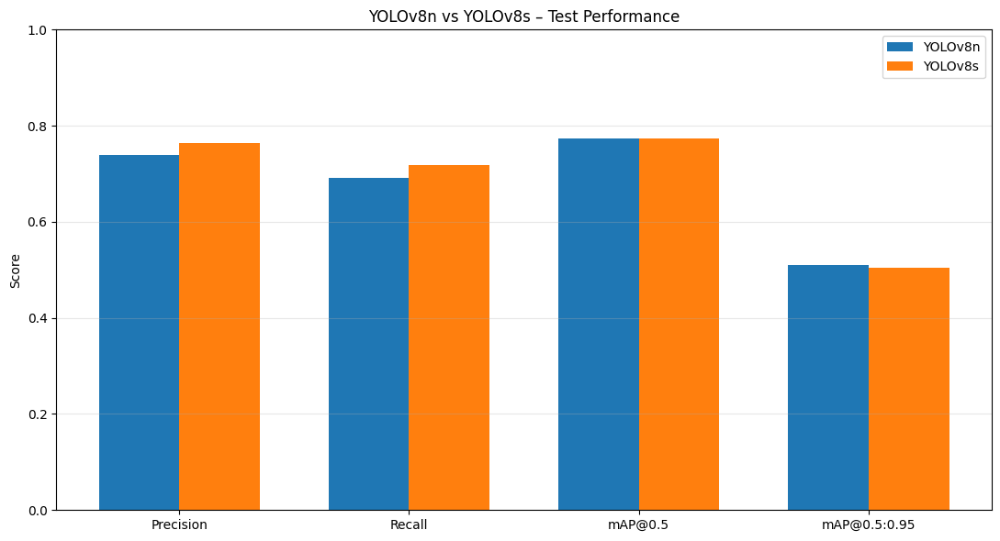

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Precision", "Recall", "mAP@0.5", "mAP@0.5:0.95"]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(x - width/2, comparison["YOLOv8n"], width, label="YOLOv8n")
plt.bar(x + width/2, comparison["YOLOv8s"], width, label="YOLOv8s")

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("YOLOv8n vs YOLOv8s – Test Performance")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

import os

def get_model_info(model, checkpoint_path):
    params = sum(p.numel() for p in model.model.parameters())
    size_mb = os.path.getsize(checkpoint_path) / (1024 ** 2)

    return {
        "Parameters (Millions)": round(params / 1e6, 3),
        "Checkpoint Size (MB)": round(size_mb, 2)
    }

info_n = get_model_info(model_n, YOLOV8N_PATH)
info_s = get_model_info(model_s, YOLOV8S_PATH)

model_info = pd.DataFrame(
    [info_n, info_s],
    index=["YOLOv8n", "YOLOv8s"]
)

print(model_info)


         Parameters (Millions)  Checkpoint Size (MB)
YOLOv8n                  3.138                  6.21
YOLOv8s                 11.136                 21.48


In [ ]:

import time
import numpy as np

def measure_inference(model, images, device):
    # Warm-up
    for img in images[:5]:
        model.predict(
            source=str(img),
            imgsz=640,
            device=device,
            verbose=False
        )

    times = []

    for img in images:
        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start = time.perf_counter()

        model.predict(
            source=str(img),
            imgsz=640,
            device=device,
            verbose=False
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        times.append(time.perf_counter() - start)

    avg_time = np.mean(times)
    fps = 1 / avg_time

    return avg_time * 1000, fps

time_n, fps_n = measure_inference(model_n, test_images, device)
time_s, fps_s = measure_inference(model_s, test_images, device)

speed_comparison = pd.DataFrame({
    "Model": ["YOLOv8n", "YOLOv8s"],
    "Inference Time (ms/image)": [time_n, time_s],
    "FPS": [fps_n, fps_s]
})

print(speed_comparison.to_string(index=False))


  Model  Inference Time (ms/image)       FPS
YOLOv8n                  24.611900 40.630752
YOLOv8s                  18.584922 53.807060


In [ ]:

final_comparison = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "mAP@0.5",
        "mAP@0.5:0.95",
        "Model Size (MB)",
        "Parameters (Millions)",
        "Inference Time (ms)",
        "FPS"
    ],
    "YOLOv8n": [
        metrics_n.box.mp,
        metrics_n.box.mr,
        metrics_n.box.map50,
        metrics_n.box.map,
        info_n["Checkpoint Size (MB)"],
        info_n["Parameters (Millions)"],
        time_n,
        fps_n
    ],
    "YOLOv8s": [
        metrics_s.box.mp,
        metrics_s.box.mr,
        metrics_s.box.map50,
        metrics_s.box.map,
        info_s["Checkpoint Size (MB)"],
        info_s["Parameters (Millions)"],
        time_s,
        fps_s
    ]
})

print(final_comparison.to_string(index=False))

final_comparison.to_csv(
    "/content/road_evaluation/final_model_comparison.csv",
    index=False
)


               Metric   YOLOv8n   YOLOv8s
            Precision  0.739210  0.764458
               Recall  0.692308  0.719064
              mAP@0.5  0.772627  0.774224
         mAP@0.5:0.95  0.511017  0.505182
      Model Size (MB)  6.210000 21.480000
Parameters (Millions)  3.138000 11.136000
  Inference Time (ms) 24.611900 18.584922
                  FPS 40.630752 53.807060


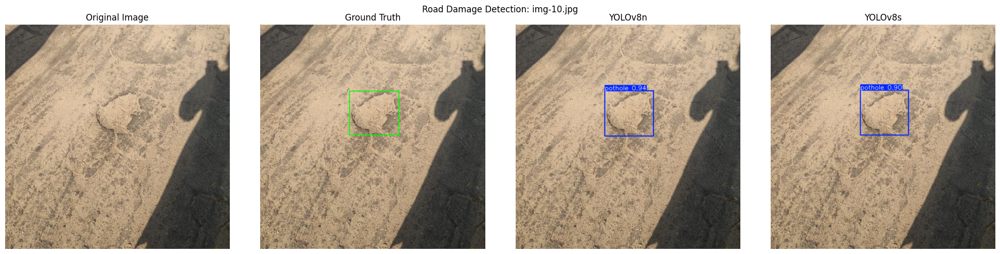

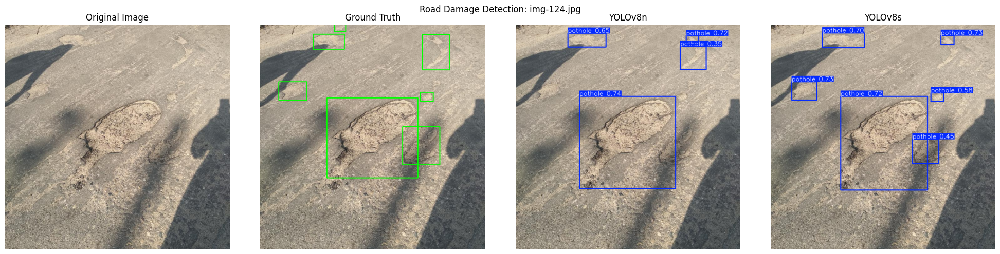

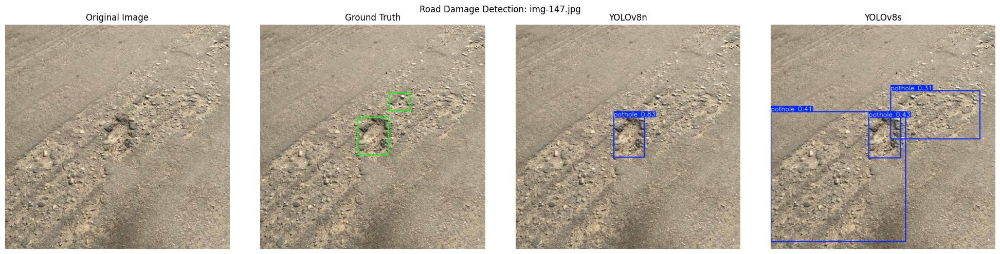

In [ ]:

import cv2
import matplotlib.pyplot as plt

def draw_ground_truth(image_path, label_path):
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w = image.shape[:2]

    with open(label_path, "r") as f:
        for line in f:
            values = list(map(float, line.split()))

            cls, xc, yc, bw, bh = values

            x1 = int((xc - bw/2) * w)
            y1 = int((yc - bh/2) * h)
            x2 = int((xc + bw/2) * w)
            y2 = int((yc + bh/2) * h)

            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

    return image

sample_indices = [0, 10, 20]

for idx in sample_indices:
    image_path = test_images[idx]
    label_path = test_label_dir / (image_path.stem + ".txt")

    original = cv2.cvtColor(
        cv2.imread(str(image_path)),
        cv2.COLOR_BGR2RGB
    )

    ground_truth = draw_ground_truth(image_path, label_path)

    pred_n = model_n.predict(
        str(image_path), conf=0.25, imgsz=640,
        device=device, verbose=False
    )[0].plot()[..., ::-1]

    pred_s = model_s.predict(
        str(image_path), conf=0.25, imgsz=640,
        device=device, verbose=False
    )[0].plot()[..., ::-1]

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    images = [original, ground_truth, pred_n, pred_s]
    titles = [
        "Original Image",
        "Ground Truth",
        "YOLOv8n",
        "YOLOv8s"
    ]

    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

    plt.suptitle(f"Road Damage Detection: {image_path.name}")
    plt.tight_layout()
    plt.show()


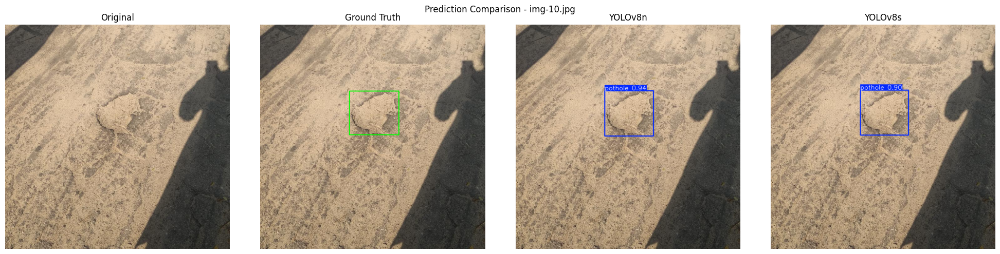

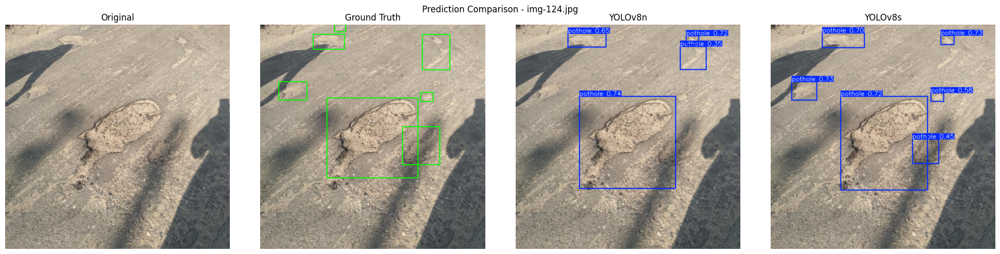

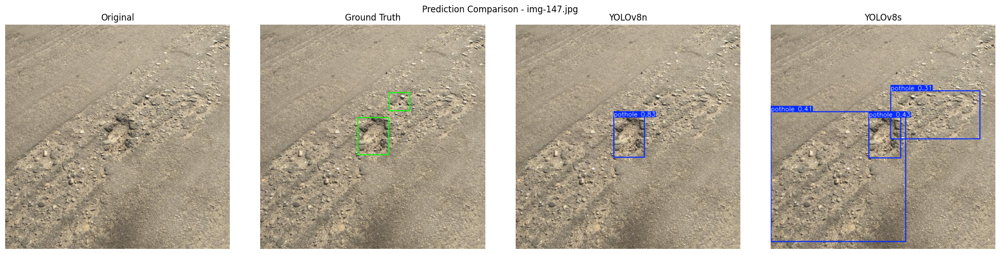

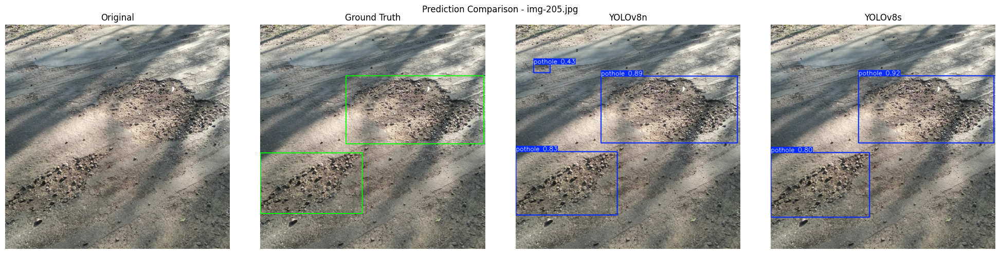

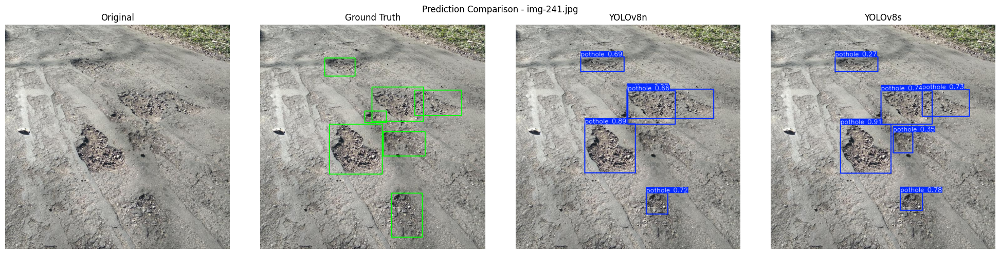

In [ ]:

import cv2
import matplotlib.pyplot as plt
import numpy as np

sample_indices = [0, 10, 20, 30, 40]

for idx in sample_indices:

    image_path = test_images[idx]
    label_path = test_label_dir / (image_path.stem + ".txt")

    original = cv2.cvtColor(
        cv2.imread(str(image_path)),
        cv2.COLOR_BGR2RGB
    )

    ground_truth = draw_ground_truth(image_path, label_path)

    pred_n = model_n.predict(
        str(image_path),
        conf=0.25,
        imgsz=640,
        device=device,
        verbose=False
    )[0].plot()[..., ::-1]

    pred_s = model_s.predict(
        str(image_path),
        conf=0.25,
        imgsz=640,
        device=device,
        verbose=False
    )[0].plot()[..., ::-1]

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    images = [original, ground_truth, pred_n, pred_s]
    titles = [
        "Original",
        "Ground Truth",
        "YOLOv8n",
        "YOLOv8s"
    ]

    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

    plt.suptitle(f"Prediction Comparison - {image_path.name}")
    plt.tight_layout()
    plt.show()


In [ ]:

from pathlib import Path

VIS_DIR = Path("/content/road_evaluation/visualizations")
VIS_DIR.mkdir(parents=True, exist_ok=True)

for idx in sample_indices:

    image_path = test_images[idx]
    label_path = test_label_dir / (image_path.stem + ".txt")

    original = cv2.cvtColor(
        cv2.imread(str(image_path)),
        cv2.COLOR_BGR2RGB
    )

    ground_truth = draw_ground_truth(image_path, label_path)

    pred_n = model_n.predict(
        str(image_path), conf=0.25,
        device=device, verbose=False
    )[0].plot()[..., ::-1]

    pred_s = model_s.predict(
        str(image_path), conf=0.25,
        device=device, verbose=False
    )[0].plot()[..., ::-1]

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    for ax, img, title in zip(
        axes,
        [original, ground_truth, pred_n, pred_s],
        ["Original", "Ground Truth", "YOLOv8n", "YOLOv8s"]
    ):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()

    output_path = VIS_DIR / f"{image_path.stem}_comparison.png"

    plt.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.close()

print("Saved visualizations:", len(list(VIS_DIR.glob("*.png"))))
print("Location:", VIS_DIR)


Saved visualizations: 5
Location: /content/road_evaluation/visualizations


In [ ]:

import numpy as np

def calculate_iou(box1, box2):
    # Boxes: x1, y1, x2, y2

    x_left = max(box1[0], box2[0])
    y_top = max(box1[1], box2[1])
    x_right = min(box1[2], box2[2])
    y_bottom = min(box1[3], box2[3])

    intersection = max(0, x_right - x_left) * max(0, y_bottom - y_top)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


In [ ]:

def load_ground_truth(label_path, width, height):
    boxes = []

    with open(label_path, "r") as f:
        for line in f:
            values = list(map(float, line.split()))

            cls, xc, yc, bw, bh = values

            x1 = (xc - bw / 2) * width
            y1 = (yc - bh / 2) * height
            x2 = (xc + bw / 2) * width
            y2 = (yc + bh / 2) * height

            boxes.append([x1, y1, x2, y2])

    return np.array(boxes).reshape(-1, 4)


def evaluate_image_predictions(pred_boxes, gt_boxes, iou_threshold=0.5):

    matched_gt = set()
    tp = 0
    fp = 0

    # Match highest-confidence predictions first
    for pred in pred_boxes:
        best_iou = 0
        best_gt = -1

        for j, gt in enumerate(gt_boxes):
            if j in matched_gt:
                continue

            iou = calculate_iou(pred, gt)

            if iou > best_iou:
                best_iou = iou
                best_gt = j

        if best_iou >= iou_threshold:
            tp += 1
            matched_gt.add(best_gt)
        else:
            fp += 1

    fn = len(gt_boxes) - len(matched_gt)

    return tp, fp, fn


In [ ]:

def run_error_analysis(model, image_paths, label_dir):

    total_tp = 0
    total_fp = 0
    total_fn = 0

    error_images = []

    for image_path in image_paths:

        label_path = label_dir / (image_path.stem + ".txt")

        image = cv2.imread(str(image_path))
        height, width = image.shape[:2]

        gt_boxes = load_ground_truth(label_path, width, height)

        result = model.predict(
            str(image_path),
            conf=0.25,
            imgsz=640,
            device=device,
            verbose=False
        )[0]

        pred_boxes = result.boxes.xyxy.cpu().numpy()

        tp, fp, fn = evaluate_image_predictions(
            pred_boxes,
            gt_boxes,
            iou_threshold=0.5
        )

        total_tp += tp
        total_fp += fp
        total_fn += fn

        if fp > 0 or fn > 0:
            error_images.append({
                "Image": image_path.name,
                "TP": tp,
                "FP": fp,
                "FN": fn
            })

    precision = total_tp / (total_tp + total_fp) if total_tp + total_fp else 0
    recall = total_tp / (total_tp + total_fn) if total_tp + total_fn else 0

    return {
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        "Precision": precision,
        "Recall": recall,
        "Error Images": error_images
    }


# Ensure this points to the top-level YOLO labels
test_label_dir = BASE_DIR / "labels" / "test"

error_n = run_error_analysis(model_n, test_images, test_label_dir)
error_s = run_error_analysis(model_s, test_images, test_label_dir)

print("YOLOv8n:", {k:v for k,v in error_n.items() if k != "Error Images"})
print("\nYOLOv8s:", {k:v for k,v in error_s.items() if k != "Error Images"})


YOLOv8n: {'TP': 234, 'FP': 111, 'FN': 65, 'Precision': 0.6782608695652174, 'Recall': 0.782608695652174}

YOLOv8s: {'TP': 223, 'FP': 94, 'FN': 76, 'Precision': 0.7034700315457413, 'Recall': 0.745819397993311}


In [ ]:

error_comparison = pd.DataFrame({
    "Metric": ["True Positives", "False Positives", "False Negatives"],
    "YOLOv8n": [
        error_n["TP"], error_n["FP"], error_n["FN"]
    ],
    "YOLOv8s": [
        error_s["TP"], error_s["FP"], error_s["FN"]
    ]
})

print(error_comparison.to_string(index=False))

error_comparison.to_csv(
    "/content/road_evaluation/error_comparison.csv",
    index=False
)


         Metric  YOLOv8n  YOLOv8s
 True Positives      234      223
False Positives      111       94
False Negatives       65       76


In [ ]:

errors_df = pd.DataFrame(
    error_n["Error Images"]
).merge(
    pd.DataFrame(error_s["Error Images"]),
    on="Image",
    how="outer",
    suffixes=("_YOLOv8n", "_YOLOv8s")
).fillna(0)

print("Images with errors:", len(errors_df))

display(errors_df.head(20))

errors_df.to_csv(
    "/content/road_evaluation/error_images.csv",
    index=False
)


Images with errors: 84


,Image,TP_YOLOv8n,FP_YOLOv8n,FN_YOLOv8n,TP_YOLOv8s,FP_YOLOv8s,FN_YOLOv8s
0,img-102.jpg,1.0,2.0,0.0,1.0,1.0,0.0
1,img-107.jpg,1.0,1.0,0.0,1.0,1.0,0.0
2,img-114.jpg,1.0,2.0,0.0,1.0,3.0,0.0
3,img-120.jpg,0.0,0.0,0.0,1.0,1.0,0.0
4,img-121.jpg,2.0,0.0,1.0,2.0,0.0,1.0
5,img-122.jpg,0.0,3.0,1.0,0.0,2.0,1.0
6,img-124.jpg,3.0,1.0,4.0,4.0,2.0,3.0
7,img-127.jpg,0.0,0.0,0.0,2.0,0.0,1.0
8,img-131.jpg,1.0,1.0,0.0,0.0,0.0,0.0
9,img-138.jpg,0.0,1.0,1.0,0.0,1.0,1.0


In [ ]:

# Calculate F1 from fixed-threshold TP, FP and FN

def calculate_f1(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return precision, recall, f1


p_n, r_n, f1_n = calculate_f1(
    error_n["TP"], error_n["FP"], error_n["FN"]
)

p_s, r_s, f1_s = calculate_f1(
    error_s["TP"], error_s["FP"], error_s["FN"]
)

error_summary = pd.DataFrame({
    "Metric": ["TP", "FP", "FN", "Precision", "Recall", "F1 Score"],
    "YOLOv8n": [
        error_n["TP"], error_n["FP"], error_n["FN"],
        p_n, r_n, f1_n
    ],
    "YOLOv8s": [
        error_s["TP"], error_s["FP"], error_s["FN"],
        p_s, r_s, f1_s
    ]
})

display(error_summary)

error_summary.to_csv(
    "/content/road_evaluation/error_analysis_summary.csv",
    index=False
)

print("Experimental error analysis saved successfully!")


,Metric,YOLOv8n,YOLOv8s
0,TP,234.000000,223.000000
1,FP,111.000000,94.000000
2,FN,65.000000,76.000000
3,Precision,0.678261,0.703470
4,Recall,0.782609,0.745819
5,F1 Score,0.726708,0.724026


Experimental error analysis saved successfully!


In [ ]:

import shutil
from google.colab import files

RESULTS_DIR = "/content/road_evaluation"

shutil.make_archive(
    "/content/road_damage_evaluation",
    "zip",
    RESULTS_DIR
)

files.download("/content/road_damage_evaluation.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>